# Лабораторная работа № 7.  Диффузионные модели

## ( “Нейросетевые технологии обработки данных”)

### студентки 4-го курса 10-ой группы

### Ярмош Алеси

### Вариант 13

Роза Гвидо Гранди (трёхлепестковая)
θ ∼ U(0, 2π), r = 3 cos 3θ, x = (r cos θ, r sin θ) + ε, ε ∼
N (0, 0.082
I)

## Постановка задачи

Реализовать на PyTorch упрощённый прямой и обратный диффузионный процесс для
генерации точек, распределённых по заданному 2D-закону из своего варианта: прямой
процесс – зашумление по линейному расписанию βt
; обратный – МСП, предсказывающий
шум (обучение по MSE), генерация – итеративное удаление шума.
Отчёт должен содержать:

1. Формулу генерации целевого распределения и визуализацию обучающей выборки.

2. Параметры расписания шума (T, β1, βT ) с обоснованием выбора и график α¯t
.

3. Архитектуру сети ϵθ(xt
, t) (структурная схема, способ подачи t на вход).

4. Кривую обучения (MSE по эпохам).

5. Визуализацию прямого процесса (зашумление при нескольких t) и обратного процесса (генерация – промежуточные состояния денойзинга и итоговое облако сгенерированных точек в сравнении с реальными).

**Импорт библиотек.** PyTorch (`torch`, `torch.nn`) — для нейросети и тензорных операций, NumPy — для генерации обучающей выборки.

In [199]:
import torch
import torch.nn as nn
import numpy as np

**Фиксация случайного зерна.** `seed(42)` для NumPy и PyTorch делает запуск воспроизводимым: выборка, инициализация весов и шум будут одинаковыми при каждом перезапуске.

In [200]:
np.random.seed(42)
torch.manual_seed(42)

**Генерация обучающей выборки (роза Гвидо Гранди).** Реализация формулы варианта: случайный угол θ ∼ U(0, 2π), радиус r = 3·cos(3θ), перевод в декартовы координаты (r·cosθ, r·sinθ) и добавление круглого гауссова шума ε ∼ N(0, 0.08²·I). Множитель 3 внутри косинуса даёт три лепестка. На выходе — массив точек формы (n, 2) в формате float32.

In [201]:
def sample_rose(n):
    teta = np.random.uniform(0, 2*np.pi, size=n)
    r = 3 * np.cos(3 * teta)
    x = np.stack([r * np.cos(teta), r * np.sin(teta)], axis=1)
    x += 0.08 * np.random.randn(n, 2)
    
    return x.astype(np.float32)

**Расписание шума и прямой процесс.**
- `X0` — обучающая выборка из 2000 точек.
- `T = 100` — число шагов диффузии; `betas` — линейное расписание силы шума от 1e-4 до 0.02.
- `alphas = 1 − betas`, `alphas_bar` — накопленное произведение ᾱₜ (сколько исходного сигнала остаётся к шагу t).
- `q_sample` — прямой процесс в замкнутой форме: за одно действие зашумляет точку до любого шага t по формуле xₜ = √ᾱₜ·x₀ + √(1−ᾱₜ)·ε. `unsqueeze(-1)` делает из ᾱₜ столбец (n, 1) для корректного броадкастинга на координаты (n, 2).

In [202]:
X0 = sample_rose(2000)

T = 100
betas = torch.linspace(1e-4, 0.02, T)
alphas = 1.0 - betas
alphas_bar = torch.cumprod(alphas, dim=0)

def q_sample(x0, t, noise):
    ab = alphas_bar[t].unsqueeze(-1)
    return torch.sqrt(ab) * x0 + torch.sqrt(1 - ab) * noise

**Визуализация прямого процесса (пункт 5 отчёта).** Берём все точки, зашумляем их до шага t=50 функцией `q_sample` и рисуем рядом: слева — чистая роза (t=0), справа — та же выборка, наполовину расплывшаяся в шум. `axis('equal')` сохраняет одинаковый масштаб осей, чтобы фигура не сплющивалась.

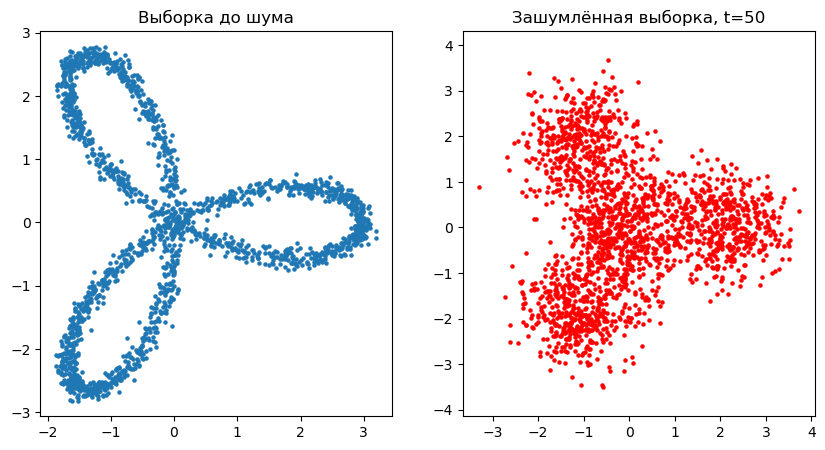

In [203]:
import matplotlib.pyplot as plt

X0_t = torch.tensor(X0)

t = torch.full((X0_t.shape[0],), 50, dtype=torch.long)
noise = torch.randn_like(X0_t)
xt = q_sample(X0_t, t, noise)

fig, ax = plt.subplots(1, 2, figsize=(10, 5))
ax[0].scatter(X0_t[:, 0], X0_t[:, 1], s=5)
ax[0].set_title('Выборка до шума')
ax[0].axis('equal')
ax[1].scatter(xt[:, 0], xt[:, 1], color='red', s=5)
ax[1].set_title('Зашумлённая выборка, t=50')
ax[1].axis('equal')
plt.show()

**Архитектура сети ϵθ (пункт 3 отчёта).** МСП, предсказывающий шум. Вход — 3 числа: координаты точки (x, y) плюс номер шага. Два скрытых слоя по 128 нейронов с ReLU, выход — 2 числа (предсказанный шум по x и y). В `forward` шаг t нормируется в [0, 1] (`t/T`), приводится к столбцу через `unsqueeze` и склеивается с координатами через `torch.cat` — так время подаётся на вход сети.

In [204]:
class EpsNet(nn.Module):
    def __init__(self, hidden=128):
        super().__init__()
        self.net = nn.Sequential(
            nn.Linear(3, hidden), nn.ReLU(),
            nn.Linear(hidden, hidden), nn.ReLU(),
            nn.Linear(hidden, 2)
        )
    
    def forward(self, x, t):
        t_norm = (t.float() / T).unsqueeze(-1)
        return self.net(torch.cat([x, t_norm], dim=-1))

model = EpsNet()

**Структурная схема сети.** `torchview` строит граф модели ϵθ. `input_size=((1,2),(1,))` задаёт два входа — батч координат (1, 2) и батч шагов (1,), как того ждёт `forward(x, t)`.

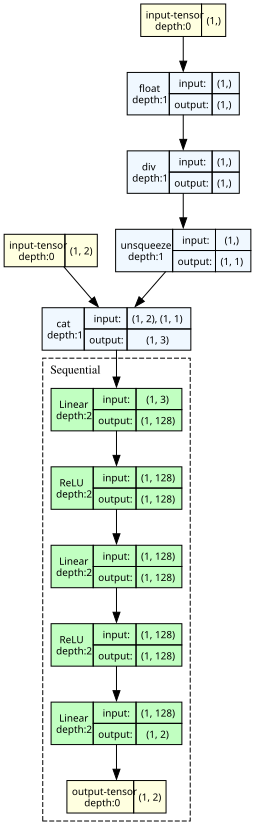

In [205]:
from torchview import draw_graph
model_graph = draw_graph(
    model,
    input_size=((1,2), (1,)), 
    graph_name="EpsNet",
    expand_nested=True
)
model_graph.visual_graph

**Оптимизатор.** Adam с шагом обучения 1e-3 — им будут обновляться веса сети при минимизации MSE.

In [206]:
opt = torch.optim.Adam(model.parameters(), lr=1e-3)

**Функция обучения.** На каждой из 3000 итераций: берётся случайный мини-батч из 256 точек, случайные шаги t и случайный шум; `q_sample` зашумляет точки до шага t; сеть предсказывает шум; считается MSE между предсказанным и настоящим шумом; делается шаг градиентного спуска. История потерь сохраняется для кривой обучения.

In [208]:
N_EPOCHS = 3000

def train(T):
    loss_hist = []

    for epoch in range(N_EPOCHS):
        idx = torch.randint(0, X0_t.shape[0], (256,))
        x0 = X0_t[idx]
        t = torch.randint(0, T, (256,))
        noise = torch.randn_like(x0)
        xt = q_sample(x0, t, noise)
        pred = model(xt, t)
        loss = ((pred - noise)**2).mean()
        opt.zero_grad(); loss.backward(); opt.step()
        loss_hist.append(loss.item())
        
    return model, loss_hist

**Запуск обучения** на T=100 шагах. Возвращает обученную модель и историю потерь.

In [209]:
model, loss_hist = train(T)

**Кривая обучения (пункт 4 отчёта).** График MSE по итерациям. Должен круто падать в начале и выходить на плато (~0.65) — признак, что сеть научилась предсказывать шум.

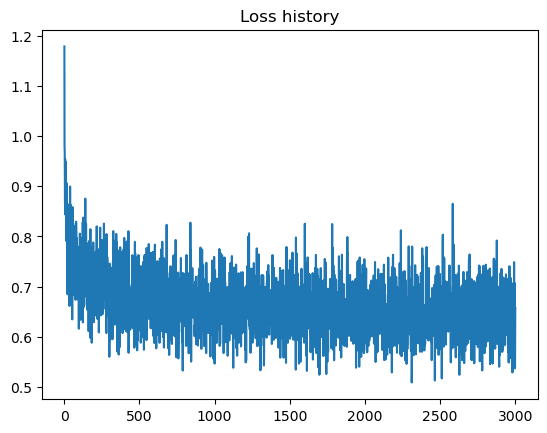

In [210]:
plt.plot(range(1, N_EPOCHS + 1), loss_hist)
plt.title('Loss history')
plt.show()

**Генерация — обратный процесс (пункт 5 отчёта).** Стартуем с чистого шума x_T ∼ N(0, I) и T раз подряд чуть-чуть его расчищаем: на каждом шаге сеть предсказывает шум, мы вычитаем его часть по формуле обратного шага и добавляем немного случайности (кроме последнего шага t=0, где нужен детерминированный результат). `@torch.no_grad()` отключает подсчёт градиентов — мы только применяем сеть, не учим. Три `print` сравнивают среднее/стд реальных и сгенерированных точек — если близки, распределение воспроизведено.

In [211]:
# 4. Генерация: последовательное удаление шума из x_T ~ N(0,I)
@torch.no_grad()
def sample(n, model, t_all):
    x = torch.randn(n, 2)
    for t in reversed(range(t_all)):
        tt = torch.full((n,), t, dtype=torch.long)
        eps_pred = model(x, tt)
        alpha_t, alpha_bar_t, beta_t = alphas[t], alphas_bar[t], betas[t]
        coef = beta_t / torch.sqrt(1 - alpha_bar_t)
        mean = (1 / torch.sqrt(alpha_t)) * (x - coef * eps_pred)
        x = mean + torch.sqrt(beta_t) * torch.randn_like(x) if t > 0 else mean
    return x.numpy()

gen = sample(2000, model, T)
print('среднее/стд обучающих данных:', X0.mean(0), X0.std(0))
print('среднее/стд сгенерированных данных:', gen.mean(0), gen.std(0))
print('средняя MSE-потеря за последние 100 эпох:', np.mean(loss_hist[-100:]))

среднее/стд обучающих данных: [-0.01789125 -0.03542191] [1.5113051 1.4985924]
среднее/стд сгенерированных данных: [ 0.05496106 -0.10782863] [1.4384571 1.4112352]
средняя MSE-потеря за последние 100 эпох: 0.6459237831830978


**Проверка формы** сгенерированного массива — должно быть (2000, 2): 2000 точек по 2 координаты.

In [212]:
gen.shape

(2000, 2)

**Итоговое облако сгенерированных точек.** Визуализация результата генерации — должна повторять форму розы из обучающей выборки.

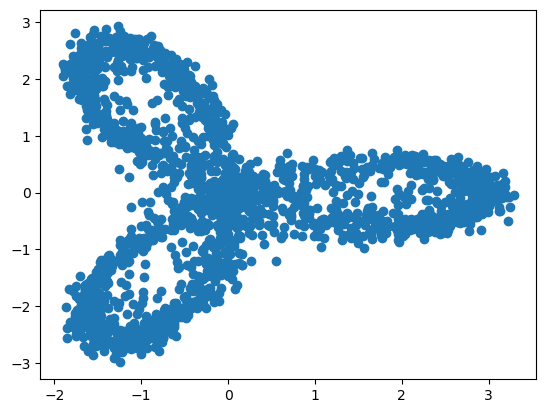

In [213]:
plt.scatter(gen[:, 0], gen[:, 1])
plt.show()

**Дополнительное задание: качество генерации vs число шагов T.** Для каждого T ∈ {10, 25, 50, 100, 200} пересобирается своё расписание шума, создаётся свежая сеть, модель обучается и генерирует точки. Качество меряется средней дистанцией от сгенерированной точки до ближайшей реальной (`cdist(...).min(axis=1).mean()`). На графике видно: при малом T качество хуже (грубый денойзинг), с ростом T улучшается и выходит на плато, а время растёт линейно (число обращений к сети на точку = T).

T= 10: средняя дистанция = 0.0609
T= 25: средняя дистанция = 0.0575
T= 50: средняя дистанция = 0.0543
T=100: средняя дистанция = 0.0507
T=200: средняя дистанция = 0.0674


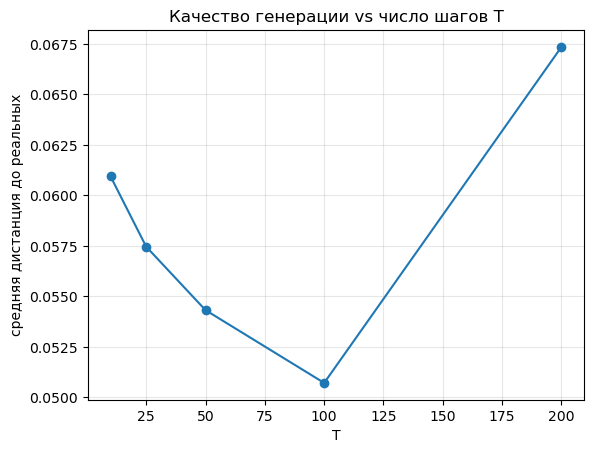

In [214]:
from scipy.spatial.distance import cdist

T_VALS = [10, 25, 50, 100, 200]
dists = []

for T_VAL in T_VALS:
    # 1. своё расписание для этого T (β-окно одно и то же)
    T = T_VAL
    betas = torch.linspace(1e-4, 0.02, T)
    alphas = 1.0 - betas
    alphas_bar = torch.cumprod(alphas, dim=0)

    # 2. свежая сеть и оптимизатор
    model = EpsNet()
    opt = torch.optim.Adam(model.parameters(), lr=1e-3)

    # 3. обучение и генерация на текущем T
    train(T)
    gen = sample(2000, model, T)

    # 4. средняя дистанция до ближайшей реальной точки
    mean_dist = cdist(gen, X0).min(axis=1).mean()
    dists.append(mean_dist)
    print(f'T={T:3d}: средняя дистанция = {mean_dist:.4f}')

plt.plot(T_VALS, dists, marker='o')
plt.xlabel('T'); plt.ylabel('средняя дистанция до реальных')
plt.title('Качество генерации vs число шагов T')
plt.grid(True, alpha=0.3)
plt.show()

## Контрольные вопросы к защите лабораторной работы

### 1. Чем прямой диффузионный процесс принципиально отличается от обратного с точки зрения того, что в нём обучаемо, а что нет?

Прямой процесс **не обучаем** — это фиксированный рецепт. Он по заранее заданному расписанию βₜ просто подмешивает гауссов шум к объекту, никаких параметров и никакого обучения в нём нет. Его можно применить к любым данным без всякой тренировки.

Обратный процесс **обучаем** — это и есть нейросеть ϵθ(xₜ, t). Она учится предсказывать шум, который был добавлен на прямом шаге, чтобы потом по нему восстанавливать менее зашумлённый объект. Вся «магия» и все веса модели сосредоточены здесь. Коротко: портить данные легко и без обучения, а восстанавливать — трудно, поэтому учимся именно откату.

### 2. Запишите замкнутую форму прямого процесса через ᾱₜ. Почему она удобнее последовательного применения формулы одного шага при обучении?

Замкнутая форма (ᾱₜ — накопленное произведение αₛ = 1−βₛ):

$$x_t = \sqrt{\bar\alpha_t}\, x_0 + \sqrt{1-\bar\alpha_t}\,\bar\epsilon,\qquad \bar\epsilon \sim \mathcal{N}(0, I)$$

Она позволяет получить зашумлённый объект на **любом** шаге t за одно действие, прямо из x₀, минуя промежуточные x₁…xₜ₋₁.

Почему это удобно при обучении: на каждой итерации мы берём случайный шаг t, и без замкнутой формы пришлось бы честно прогонять цикл из t последовательных зашумлений для каждого примера — медленно и бессмысленно. А так — одна формула, один шаг, сразу нужный xₜ. Это делает обучение быстрым и векторизуемым по всему батчу.

### 3. Почему сеть обучают предсказывать шум ϵ, а не напрямую менее зашумлённый объект xₜ₋₁?

Две причины. Во-первых, шум — это «ровная» мишень одного и того же масштаба (N(0, I)) на всех шагах t, её сети предсказывать удобно и стабильно, тогда как сам xₜ₋₁ меняет масштаб и вид в зависимости от шага. Во-вторых, предсказание шума не теряет информации: зная предсказанный ϵ, менее зашумлённый объект восстанавливается по формуле обратного шага — одно однозначно выражается через другое.

По сути это как скульптор, который отсекает лишнее по кусочку, а не пытается изваять шедевр одним движением: «убери понемногу известный шум» — задача куда проще, чем «нарисуй сразу чистый объект».

### 4. Зачем сети ϵθ(xₜ, t) нужен номер шага t на входе (временной эмбеддинг)? Что произойдёт, если его не передавать?

Потому что количество шума в xₜ сильно зависит от t: «чуть зашумлённый» объект и «почти чистый шум» требуют совершенно разной силы вычитания. Номер шага говорит сети, на каком этапе денойзинга она находится, чтобы она применяла правильную поправку.

Без t сеть не знает своего положения в процессе и вынуждена применять одну усреднённую поправку ко всем уровням зашумления. Для сильно зашумлённых входов она будет вычитать слишком мало, для почти чистых — слишком много, и генерация развалится. В нашей задаче t подаётся просто как t/T ∈ [0, 1] — третьим входом рядом с координатами точки.

### 5. Почему функция потерь диффузионной модели (MSE) считается более устойчивой для обучения, чем минимаксная функция потерь GAN?

Диффузия решает **одну** задачу — регрессию «предскажи шум» с обычным MSE между истинным и предсказанным шумом. Это выпуклая, гладкая, хорошо ведущая себя цель с понятным минимумом, и обучается она спокойно и предсказуемо.

У GAN же две сети в минимаксной игре: генератор и дискриминатор соревнуются, и обучение ищет хрупкое равновесие, а не минимум одной функции. Отсюда типичные проблемы — расхождение, осцилляции, коллапс мод, насыщение градиента. В диффузии нет этой «гонки вооружений»: одна сеть, честный MSE, никаких конкурирующих целей — поэтому обучение заметно устойчивее.

### 6. Опишите формулу одного шага обратного (генеративного) процесса. Почему при t = 1 стохастическая добавка отсутствует?

Шаг денойзинга (переход от xₜ к xₜ₋₁):

$$x_{t-1}=\frac{1}{\sqrt{\alpha_t}}\Big(x_t-\frac{\beta_t}{\sqrt{1-\bar\alpha_t}}\,\epsilon_\theta(x_t,t)\Big)+\sigma_t z,\qquad z \sim \mathcal{N}(0,I)$$

Первое слагаемое — детерминированная часть: берём текущий xₜ, вычитаем предсказанную долю шума и перемасштабируем, получая оценку среднего для xₜ₋₁. Второе слагаемое σₜz — добавка контролируемой случайности, которая поддерживает стохастичность процесса и даёт разнообразие образцов.

При t = 1 (последний шаг, переход к чистому x₀) стохастическую добавку выключают (z = 0). Дальше чистить уже некуда, и нужен финальный детерминированный результат — лишняя случайность на последнем шаге только зашумляла бы готовый объект.

### 7. Почему генерация в диффузионной модели требует T последовательных проходов через сеть, а не одного прохода, как в GAN?

Потому что диффузия намеренно разбила сложную задачу «шум → объект» на T маленьких посильных шажков. Каждый вызов сети делает только один крошечный шаг денойзинга — предсказывает шум на текущем уровне и чуть-чуть его убирает, — а результат подаётся обратно в сеть для следующего шага. Эти шаги зависят друг от друга последовательно, поэтому их нельзя выполнить параллельно или за один проход.

GAN же обучен отображать шум в объект за **один** проход генератора, без итераций. Это делает генерацию GAN быстрее, но ценой устойчивости обучения; диффузия идёт на T проходов ради стабильности и качества. (Число обращений к сети на одну точку = T, поэтому время сэмплирования растёт линейно по T.)